# Lab 1: Introduction to linear regression with one variable
Àlex Font Bartumeus

Iris Azlor Solé

### 2.1 Problem formulation
Suppose you are working in a healthcare analytics team. You already have access to the
medical history from various patients and have collected data on the age of admitted
patients and the duration of their hospitalization. Your goal is to **train a model that can
predict the expected length of stay for a new patient**, so this information can be used to
optimize resource allocation and patient care.

In [ ]:
# We start by importing the needed libraries
import numpy as np
import matplotlib.pyplot as plt

## 2.2 LOAD AND SPLIT THE DATASET ##

# Load the datase
data=np.loadtxt("synthetic_patients.txt", delimiter= ",")
print(data.shape)

# The dataset is composed of 500 rows and 2 columns. We separate it in two sets:
# 400 to train the models and 100 to evaluate their performance.
train_data, test_data = data[:400], data[400:]

# x = age
# y = length of stay
# We divide training and test data into age and length of stay
train_x=train_data[:,0] # first column contains age
train_y=train_data[:,1] # second column contains length of stay
test_x = test_data[:,0]
test_y = test_data[:,1]

print('Train: ', train_x.shape, train_y.shape)
print('Test: ', test_x.shape, test_y.shape)


(500, 2)
Train:  (400,) (400,)
Test:  (100,) (100,)


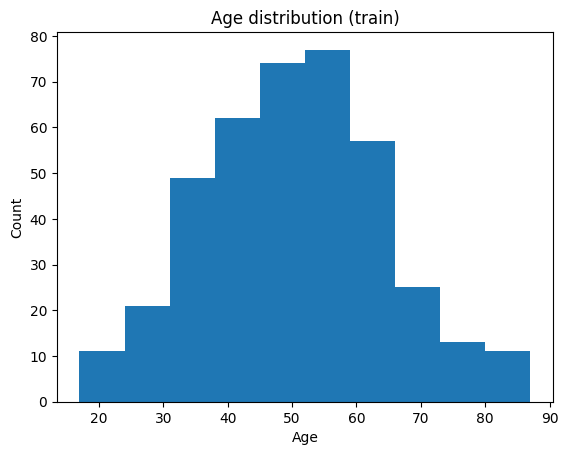

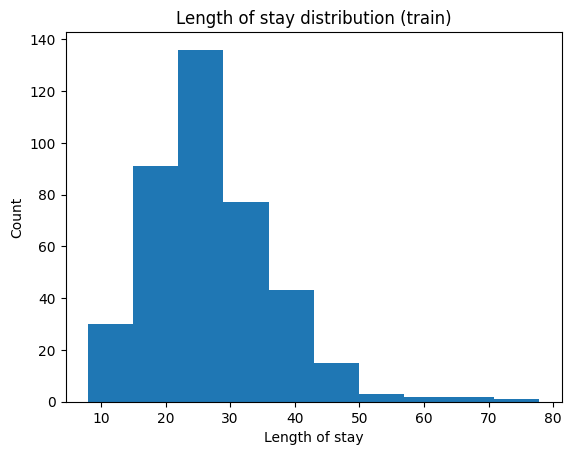

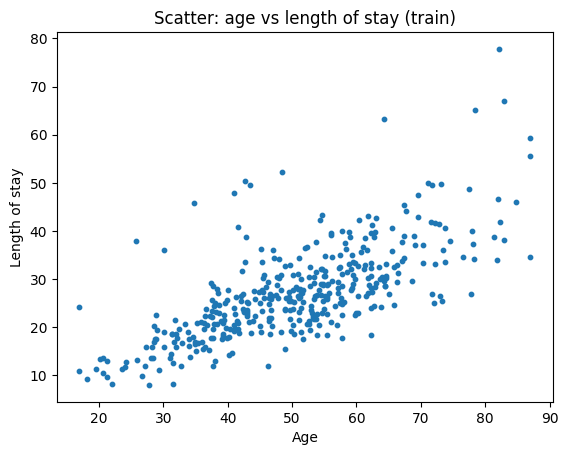

In [ ]:
## 2.3 VISUALIZE THE DATA ##
# We start by plotting the distribution of age and length of stay with an histogram
plt.figure()
plt.hist(train_x, bins=10)
plt.title("Age distribution (train)")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

plt.figure()
plt.hist(train_y, bins=10)
plt.title("Length of stay distribution (train)")
plt.xlabel("Length of stay")
plt.ylabel("Count")
plt.show()

# We also generate a scatter plot with one variable per axis in order to study
# the association between the target and the input variable.
plt.figure()
plt.scatter(train_x, train_y, s=10)
plt.title("Scatter: age vs length of stay (train)")
plt.xlabel("Age")
plt.ylabel("Length of stay")
plt.show()

We see how the age plot looks like a Normal Gaussian distribution. However, when it comes to the length of stay the distribution is different and is skewed to the left.
Nevertheless, the last plot indicates a linear correlation between the variables.

In [ ]:
## 2.4 EXPRESS THE MODEL AS A MATRIX MULTIPLICATION ##

# To account for both the intercept and slope of the linear model, we augment the
# input feature with a constant term

# We implement a design matrix by stacking a column of ones to our original input
# matrix
X_train = np.column_stack((np.ones(len(train_x)), train_x))
X_test  = np.column_stack((np.ones(len(test_x)),  test_x))

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (400, 2) X_test: (100, 2)


theta: [0.01023368 0.53539021]


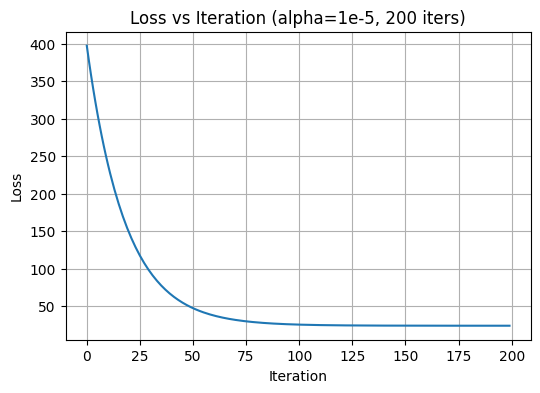

In [ ]:
## 2.5 IMPLEMENT THE GRADIENT DESCENT ALGORITHM ##
# The goal is to minimize the loss function by finding the right bias and
# slope

# 1st: Implement the Loss Function --> J(theta) = 1/(2n)*||Xtheta - y||^2

def loss_function(X, y, theta):
  # X: matrix
  # y: vector
  # theta: parameter vector
  # output: associated prediction error
  predictions = X @ theta
  errors = predictions - y
  return (1/(2*len(errors)))*np.sum(errors**2)

# 2nd: Implement the function for the optimization loop
# As an output, the function should provide both the last version of the
# parameter vector and the history of recorded losses
def gradient_descent(X, y, learning_rate, num_of_iterations):
  theta = np.zeros(2,)
  J_arr= np.zeros(num_of_iterations)

  for i in range(num_of_iterations):
    predictions = X @ theta
    errors = predictions - y
    theta = theta - learning_rate * (1/len(errors)) * (X.T @ errors) # update theta values
    J_arr[i] = loss_function(X, y, theta) # update cost function value for each iteration
  return theta, J_arr

## 2.6 RUN THE OPTIMIZATION PROCESS ##

# alpha = learning_rate

parameters, loss_history = gradient_descent(X_train,train_y, learning_rate=1e-5, num_of_iterations=200)
print("theta:", parameters)

plt.figure(figsize=(6,4))
plt.plot(loss_history)
plt.title("Loss vs Iteration (alpha=1e-5, 200 iters)")
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.grid(True)
plt.show()


This plot illustrates the evolution of the loss function values as the iterations increase. It shows us how at first each iteration (update of the parameters) causes a fast decay of the loss function but then the it converges as each iteration and parameter update causes very small decreases to its value.

Model prediction for a patient aged 58:  31.06286603149648 days
Model prediction for patient aged 25:  13.394989005922723 days

Model evaluation

 * Model MAE 4.677786053610186
 * Baseline MAE 7.2320500099629825


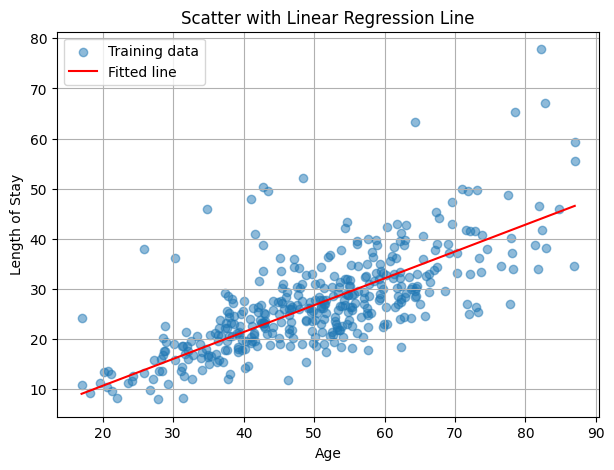

In [ ]:
## 2.7 TEST YOUR MODEL ##

#After training the model, it can be evaluated on examples that were not used
#during the learning process. This allows us to assess its generalization ability and
#predictive performance.

# In order to inspect the performance, we plot the line obtained on the original
# scater plott.

X_test=np.column_stack((np.ones(len(test_x)), test_x))
test_predictions = X_test @ parameters
print('Model prediction for a patient aged 58: ', parameters[0] + 58 * parameters[1], 'days')
print('Model prediction for patient aged 25: ', parameters[0] + 25 * parameters[1], 'days\n')
print('Model evaluation\n')
print(' * Model MAE', np.mean(abs(test_predictions - test_y)))
print(' * Baseline MAE', np.mean(abs(train_y.mean()-test_y)))

# SCATTER PLOT
plt.figure(figsize=(7,5))
plt.scatter(train_x, train_y, alpha=0.5, label='Training data')

x_values_for_line = np.array([train_x.min(), train_x.max()])
y_values_for_line = parameters[0] + parameters[1] * x_values_for_line
plt.plot(x_values_for_line, y_values_for_line, color='red', label='Fitted line')

plt.title('Scatter with Linear Regression Line')
plt.xlabel('Age')
plt.ylabel('Length of Stay')
plt.legend()
plt.grid(True)
plt.show()

In order to test our model we compute the model's MAE and compare it to the previously stablished baseline MAE obtaining a smaller MAE for our model's fitting. This can be seen more clearly in the plot showing the fitted line obtained after training the model and comparing it to the training data scatter plot.

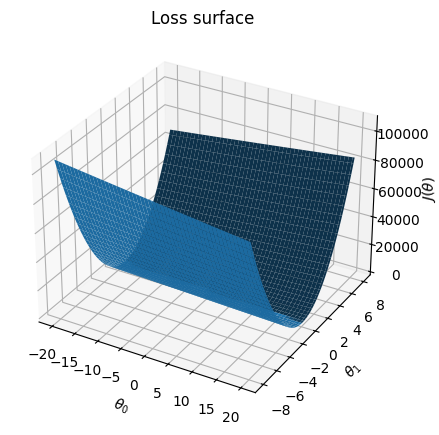

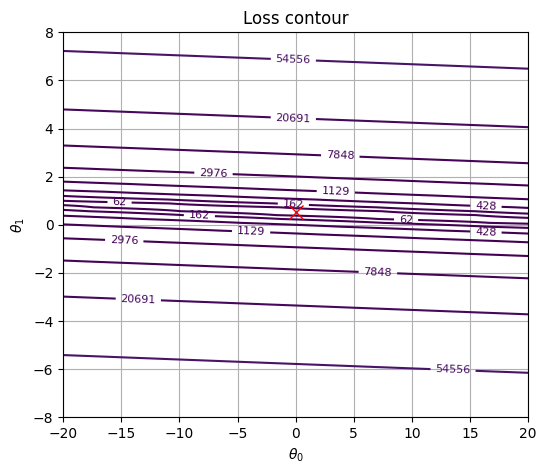

In [ ]:
## 2.8 TAKE A CLOSER LOOT AT THE LOSS FUNCTION ##

# Evaluation of the loss function in detail
# We create a grid that spans 100 values for theta0 and theta1. We then try values
# ranging from -20 to 20 for the first and -8 to 8 for the sencond.
from mpl_toolkits.mplot3d import Axes3D

def compute_loss_landscape(X,y, theta_0, theta_1):
  J =np.zeros((len(theta_0), len(theta_1)))
  for i in range(len(theta_0)):
    for j in range(len(theta_1)):
      J[i,j] = loss_function(X, y, np.array([theta_0[i], theta_1[j]]))
  return J

def plot_loss_function(X,y,theta):
  theta_0, theta_1 = np.linspace(-20,20,100), np.linspace(-8,8,100)

  J = compute_loss_landscape(X, y, theta_0, theta_1)

  theta_0_grid, theta_1_grid = np.meshgrid(theta_0, theta_1, indexing="ij")

  fig = plt.figure(figsize=(7,5))
  ax = fig.add_subplot(111, projection='3d')
  ax.plot_surface(theta_0_grid, theta_1_grid, J, rstride=2, cstride=2, linewidth=0, antialiased=True)
  ax.set_xlabel(r'$\theta_0$')
  ax.set_ylabel(r'$\theta_1$')
  ax.set_zlabel(r'$J(\theta)$')
  ax.set_title('Loss surface')
  plt.show()


 # Contour
  plt.figure(figsize=(6,5))
  levels = np.logspace(-2, 6, 20)  # ajusta si hace falta
  cs = plt.contour(theta_0_grid, theta_1_grid, J, levels=levels)
  plt.clabel(cs, inline=1, fontsize=8)

  plt.plot(theta[0], theta[1], 'rx', markersize=10)

  plt.xlabel(r'$\theta_0$')
  plt.ylabel(r'$\theta_1$')
  plt.title('Loss contour')
  plt.grid(True)
  plt.show()

# Llamada (fuera de las funciones)
plot_loss_function(X_train, train_y, parameters)

Looking at the plot of the three dimensional surface of the loss function we see it resembles a kind of parabola-like valley which makes a lot of sense since the cost function is the mean squared error.

However, the contour plot shows a valley very wide for the bias parameter and very thin in the vertical axis. It is a disproportionate valley much more esxtensive in one dimension than the other. This can cause problems for the gradient descent algorithm not allowing it to converge for steps too large or taking too long to converge for small steps.

Model evaluation

 * Model MAE 7.010594736949219
 * Baseline MAE 7.2320500099629825
Model prediction for a patient aged 58:  27.42916499496678 days
Model prediction for patient aged 25:  26.638466038288183 days


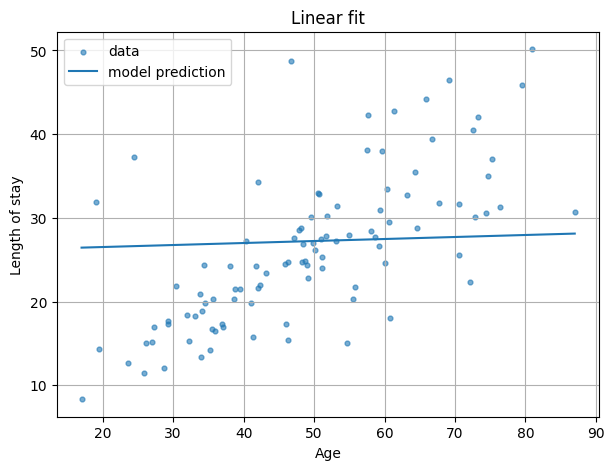

In [ ]:
#See what happens if you run the optimization process again, but with a higher
#learning rate of α = 1 · 10−3. Plot the loss convergence plot.

xmean = train_x.mean()
x_std = train_x.std()
ymean = train_y.mean()
y_std = train_y.std()

def standarize(v,mean,std):
  return((v-mean)/std)

def destandarize(v,mean,std):
  return(v*std+mean)

standard_train_x = standarize(train_x, xmean, x_std)
standard_train_y = standarize(train_y, ymean, y_std)

standard_X_train = np.column_stack([np.ones(len(train_x)), standard_train_x])


theta_std, loss_std = gradient_descent(standard_X_train, standard_train_y,learning_rate=1e-3, num_of_iterations=50)


standard_X_test = np.column_stack([np.ones(len(test_x)), standarize(test_x, xmean, x_std)])

test_predictions = destandarize(standard_X_test @ theta_std, ymean, y_std)

print('Model evaluation\n')
print(' * Model MAE', np.mean(np.abs(test_predictions - test_y)))
print(' * Baseline MAE', np.mean(np.abs(train_y.mean() - test_y)))

def predict_with_standarization(x_value, theta):
    theta = np.array(theta).reshape(-1)
    standard_input = standarize(x_value, xmean, x_std)
    standard_prediction = theta[0] + standard_input * theta[1]
    return destandarize(standard_prediction, ymean, y_std)

print('Model prediction for a patient aged 58: ', predict_with_standarization(58, theta_std), 'days')
print('Model prediction for patient aged 25: ', predict_with_standarization(25, theta_std), 'days')



def plot_linear_fit(x, y, y_pred):
    plt.figure(figsize=(7,5))
    plt.scatter(x, y, s=12, alpha=0.6, label="data")

    # ordenar por x para que la línea salga bien
    order = np.argsort(x)
    plt.plot(x[order], y_pred[order], label="model prediction")

    plt.title("Linear fit")
    plt.xlabel("Age")
    plt.ylabel("Length of stay")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_linear_fit(test_x, test_y, test_predictions)



This plot is a good example of the model not being able to converge on a low cost function value when there is no feature normalization and we use a higher learning rate.

theta (standarized):  [-3.17385007e-17  7.02975701e-01]


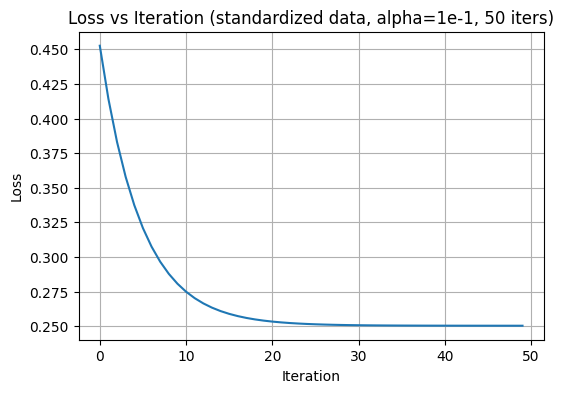

Model evaluation

 * Model MAE 4.620666333235296
 * Baseline MAE 7.2320500099629825


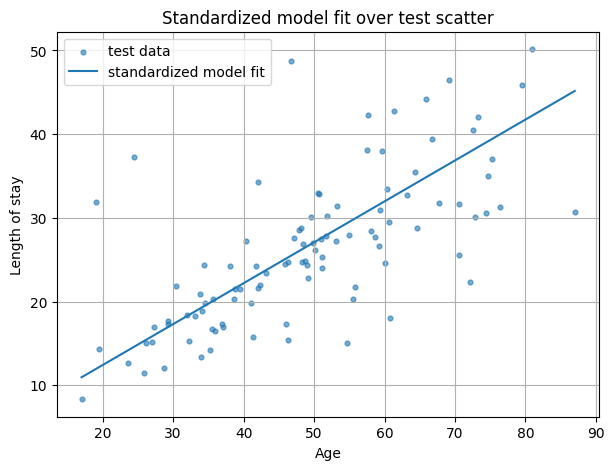

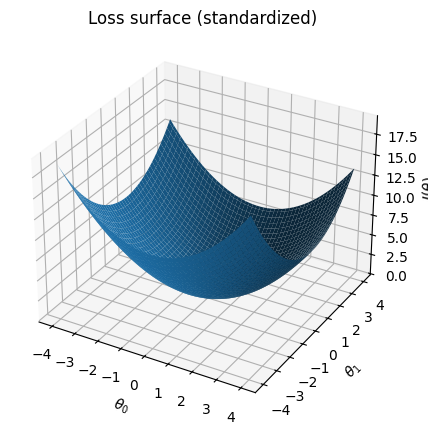

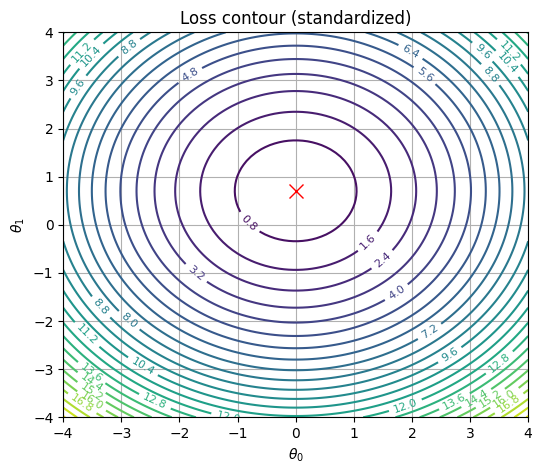

In [ ]:
## 2.9 STUDY THE EFFECTS OF FEATURE NORMALIZATION ##

# Let's standarize the data by altering its shape and making it more regular
# We start by standarizing the age and length of stay in the training set by
# subtracting their mean and dividing by their standard deviation

xmean = train_x.mean()
x_std = train_x.std()
ymean = train_y.mean()
y_std = train_y.std()

def standarize(v,mean,std):
  return((v-mean)/std)

def destandarize(v,mean,std):
  return(v*std+mean)

standard_train_x = standarize(train_x, xmean, x_std)
standard_train_y = standarize(train_y, ymean, y_std)

standard_X_train = np.column_stack([np.ones(len(train_x)), standard_train_x])


theta_std, loss_std = gradient_descent(standard_X_train, standard_train_y,learning_rate=1e-1, num_of_iterations=50)

print("theta (standarized): ", theta_std)
plt.figure(figsize=(6,4))
plt.plot(loss_std)
plt.title("Loss vs Iteration (standardized data, alpha=1e-1, 50 iters)")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.grid(True)
plt.show()


standard_X_test = np.column_stack([np.ones(len(test_x)), standarize(test_x, xmean, x_std)])

test_predictions = destandarize(standard_X_test @ theta_std, ymean, y_std)

print('Model evaluation\n')
print(' * Model MAE', np.mean(np.abs(test_predictions - test_y)))
print(' * Baseline MAE', np.mean(np.abs(train_y.mean() - test_y)))

plt.figure(figsize=(7,5))
plt.scatter(test_x, test_y, s=12, alpha=0.6, label="test data")

x_line = np.array([test_x.min(), test_x.max()])
X_line_std = np.column_stack((np.ones(len(x_line)), standarize(x_line, xmean, x_std)))
y_line = destandarize(X_line_std @ theta_std, ymean, y_std)

plt.plot(x_line, y_line, label="standardized model fit")
plt.title("Standardized model fit over test scatter")
plt.xlabel("Age"); plt.ylabel("Length of stay")
plt.grid(True); plt.legend()
plt.show()


def plot_loss_function_std(X, y, theta):
  theta_0 = np.linspace(-4, 4, 100)
  theta_1 = np.linspace(-4, 4, 100)

  J = compute_loss_landscape(X, y, theta_0, theta_1)

  theta_0_grid, theta_1_grid = np.meshgrid(theta_0, theta_1, indexing="ij")

  # Surface
  fig = plt.figure(figsize=(7,5))
  ax = fig.add_subplot(111, projection='3d')
  ax.plot_surface(theta_0_grid, theta_1_grid, J, rstride=2, cstride=2, linewidth=0, antialiased=True)
  ax.set_xlabel(r'$\theta_0$')
  ax.set_ylabel(r'$\theta_1$')
  ax.set_zlabel(r'$J(\theta)$')
  ax.set_title('Loss surface (standardized)')
  plt.show()

  # Contour
  plt.figure(figsize=(6,5))
  cs = plt.contour(theta_0_grid, theta_1_grid, J, levels=30)
  plt.clabel(cs, inline=1, fontsize=8)

  plt.plot(theta[0], theta[1], 'rx', markersize=10)
  plt.xlabel(r'$\theta_0$')
  plt.ylabel(r'$\theta_1$')
  plt.title('Loss contour (standardized)')
  plt.grid(True)
  plt.show()

plot_loss_function_std(standard_X_train, standard_train_y, theta_std)



When the features are normalized we see how the cost function takes a smaller number of iterations to converge and we obtain a smaller MAE than we did before. Thus, the standardized model fits better to the test data. Finally, we can visualize the effects of the normalization of the features resulting on a valley that extends equally for both age and length of stay which is very clear in the loss contour where now we have numerous concentric circle with decreasing cost function values leading to the minimum.



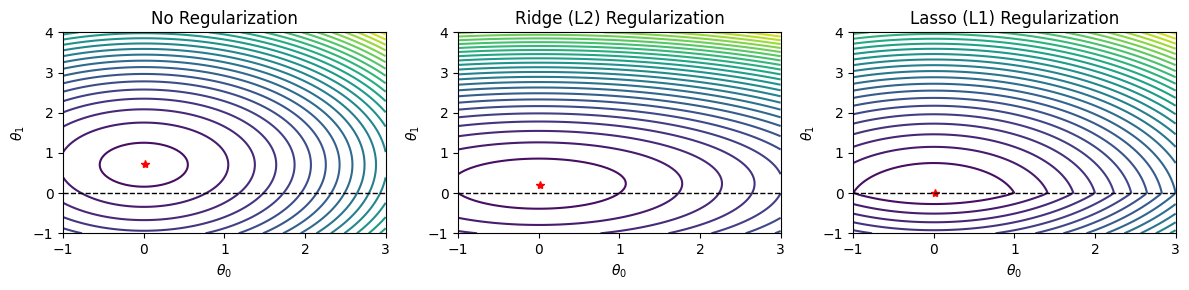

In [ ]:
## 2.10 STUDY THE EFFECTS OF REGULARIZATION ##

# We will create two extra variations of the parameter-loss grid we had generated in
# section 2.9: one with ridge regularization and one with lasso regularization.

# Lambda encodes regularization strength
xmean = train_x.mean()
x_std = train_x.std()
ymean = train_y.mean()
y_std = train_y.std()

standard_train_x = standarize(train_x, xmean, x_std)
standard_train_y = standarize(train_y, ymean, y_std)
standard_X_train = np.column_stack([np.ones(len(train_x)), standard_train_x])


theta_0 = np.linspace(-1,3,100)
theta_1 = np.linspace(-1,4,100)
loss_landscape = compute_loss_landscape(standard_X_train, standard_train_y, theta_0, theta_1)
theta_0_grid, theta_1_grid = np.meshgrid(theta_0,theta_1, indexing = 'ij')

def compare_regularization_effects(J, strength = 1.0):

  J=J.reshape(theta_0_grid.shape) # in case J does not have the shape (len(theta_0), len(theta_1))

  L2_penalty = strength * (theta_1_grid**2)
  L1_penalty = strength * np.abs(theta_1_grid)

  fig,axes = plt.subplots(1,3,figsize=(12,3))
  titles = ['No Regularization', 'Ridge (L2) Regularization', 'Lasso (L1) Regularization']
  losses = [J, J+L2_penalty, J+L1_penalty]

  for ax, regularized_J, title in zip(axes, losses, titles):
    ax.contour(theta_0_grid, theta_1_grid, regularized_J, levels=30)
    ax.set_title(title)
    ax.set_xlabel(r'$\theta_0$')
    ax.set_ylabel(r'$\theta_1$')

    # to mark min on the grid
    min_idx = np.unravel_index(np.argmin(regularized_J), regularized_J.shape)
    ax.plot(theta_0[min_idx[0]], theta_1[min_idx[1]], 'r*')

    ax.axhline(0,color='black', lw=1, ls='--')


  plt.tight_layout()
  plt.show()

compare_regularization_effects(loss_landscape, strength=1.0)


### 3 ASSESSMENT

**1. Why are we splitting the data into a training and test set?**

Because to train a model we first need a training set that allows us to train the model's parameters, and then we need a test set to evaluate how well the model generalizes to unseen data. In our case, out of 500 cases, we used 400 for training and 100 for testing.

**2. What type of distribution do the age and length of stay follow (approximately)?**

For age, we have approximately a unimodal and fairly symmetric distribution. In contrast, for length of stay, we follow a left-skewed distribution, since the data can range from a few  to many days of stay.

**3. What are the mean and median of age and of length of stay?**

Age mean: 50.332 | median: 50.888

Length of stay mean: 27.245 | median: 26.269

In [ ]:
# Code for question 3
mean_age, median_age = train_x.mean(), np.median(train_x)
mean_length, median_length = train_y.mean(), np.median(train_y)

print(f"Age mean: {mean_age:.3f} | median: {median_age:.3f}")
print(f"Length of stay mean: {mean_length:.3f} | median: {median_length:.3f}")


Age mean: 50.332 | median: 50.888
Length of stay mean: 27.245 | median: 26.269


**4. What is the most important qualitative difference between the two distributions?**


The most significant qualitative difference between the distributions is skewness. When we look at the mean and median values ​​for age, we see that they are approximately equal (mean≈median) , which means that their distribution is quite symmetrical. However, when we look at length of stay, we see that mean > median. This means that there are some patients with very long stays who pull the mean upwards, which is known as right-skew.

**5. Are there atypical patients? Present a couple of them. How does the model
perform when tested on these patients?**

Yes, atypical patients are those at the extremes of the distribution. These patients may be atypical because they are very young or very old, or because they have extremely long lengths of stay.

Let's look at these two examples of atypical patients:

In [ ]:
# Atypical patient with extreme age (youngest and oldest)

idx_young = np.argmin(test_x) # we use text_x for the age
idx_old   = np.argmax(test_x)

idx_age = idx_young   # we can change it here for idx_old to have the oldest patient

age_ext = test_x[idx_age]
los_true_ext = test_y[idx_age] # we look for the true length of the stay for this patient
los_pred_ext = np.array([1, age_ext]) @ parameters # we predict the length of the stay based on the age
abs_err_ext = abs(los_pred_ext - los_true_ext) # we compute how does the model perfomed on this patient

print("Atypical patient: extreme age")
print(f"  Age (years): {age_ext:.3f}")
print(f"  True length of stay: {los_true_ext:.3f}")
print(f"  Predicted length of stay: {los_pred_ext:.3f}")
print(f"  Absolute error (days): {abs_err_ext:.3f}")


# Atypical patient with longest length of stay

idx_long = np.argmax(test_y) # we use test_y for the length of stay

los_true_long = test_y[idx_long]
los_pred_long = np.array([1, test_x[idx_long]]) @ parameters
abs_err_long = abs(los_pred_long - los_true_long)

print("\nAtypical patient: longest stay")
print(f"  True length of stay: {los_true_long:.3f}")
print(f"  Predicted length of stay: {los_pred_long:.3f}")
print(f"  Absolute error (days): {abs_err_long:.3f}")


Atypical patient: extreme age
  Age (years): 17.000
  True length of stay: 8.342
  Predicted length of stay: 9.112
  Absolute error (days): 0.770

Atypical patient: longest stay
  True length of stay: 50.142
  Predicted length of stay: 43.329
  Absolute error (days): 6.813


If we look for the atypical patient with extreme age we identify that the youngest patient is 17 years old (mean ≈ 50 years old). For this patient, the true length of stay is approximately 8 days, however, the model predicts a stay of 9 days. Therefore, the error in the performance of the model is of less than a day.

If, on the contrary, we look at the atypical patient with the longest stay we will see that the true length of stay is of approximately 50 days (mean ≈ 27 days) but the model predicts a stay of 43 days giving an error of almost 7 days.


Here, we have optained that an atypical patient when it comes to age would be the patient with index 71, which is 17 years old.
If we look for the patient with the longest stay it would be in this case 50 days.

**6. When training a model with standardized data, what is the effect on convergence?**

Standardizing data involves transforming the variables so they are centered and rescaled. In practice, this standardization means that for each variable, we subtract its mean and divide by its standard deviation.

Once standardization is applied, the data has a mean close to 0 and a standard deviation close to 1. The goal of this process is to obtain the variables on a comparable scale without changing the relationship between them.

Standardization has a direct effect on the convergence of gradient descent, especially on the loss function. When we use unstandardized data, the loss function is poorly conditioned. As a consequence, it may require many iterations to reach the minimum, and if the learning rate is very high, it can become unstable. In contrast, with standardized data, the loss landscape is better conditioned, allowing gradient descent to converge more smoothly and often faster; fewer iterations are needed to reach the optimal value.

**7. How is that model performing in comparison to the original one?**

The standarized model performs similarly to the orginal one (non-standardized) but the results obtained ar slightly better.



*   Original model: MAE 4.677786053610186, Baseline MAE 7.2320500099629825
*   Standardized model: MAE 4.620666333235296, Baseline MAE 7.2320500099629825


The results show that the MAE (Maximum Average Equivalent) decreases from approximately 4,678 days to 4,621 days, while the baseline remains at 7,232 days. Therefore, we can see that the standardized model performs better, and that in both cases, both models outperform the baseline.

It is also important to note that both models were trained with different parameters, since the standardization process involved changing the scale of the variables. In the original model, we used a very low learning rate (1e-5) and many more iterations (200). In the standardized model, we used a much higher learning rate (1e-1) and fewer iterations (50) while achieving comparable and better test performance.

**8. Looking at the two previous questions, what are the potential benefits?**

One potential benefit we derive from the two previous questions is that using standardization makes the optimization process much easier and more robust. Through the process of rescaling and centering the data, the loss surface becomes more consistent and better conditioned. As a result, the gradient descent converges more smoothly, and the chosen learning rate is less sensitive.

This potential can be observed in the results of question 8, where we see that the original model requires a very small learning rate and many iterations to remain stable. In contrast, the standardized model yields a slightly improved value with a higher learning rate and fewer iterations. This would imply faster training and less risk of divergence.

**9. What common effect do both regularization methods induce in the loss function?**

Both the Ridge and Lasso regularization methods modify the loss function by adding a penal term. This term discourages large parameter values. Essentially, these methods ensure that the loss not only measures how well the model fits the data but also how complex the model is in terms of parameter magnitude.

As a result, both regularization methods work to push the optimal value obtained towards smaller values ​​of the slope parameter theta_1. The graph in section 2.10 illustrates this:


*   **No regularization**: the minimum falls to approximately 0.7, which
corresponds to a 'free' theta1. This is the fit that best minimizes the MSE without any penalty.
*   **Ridge regularization**: the minimum shifts smoothly towards theta_1 = 0. Since Ridge penalizes theta_1^2, the slope is reduced, but it doesn't reach 0.
*   **Lasso regularization**: the minimum falls much closer to theta_1 = 0 than in the Ridge case. In this case, the value would be practically 0. This is the normal behavior for Lasso regularization; the slope is pushed to zero.

**10. What is the most important difference between the two?**

The most important difference between the two is the nature of the penalty applied to the model. Ridge regularization, known as L2, penalizes the squared magnitude of the theta1 parameter, which encourages smaller values but typically keeps them non-zero as shown in the middle plot. On the other hand, Lasso regularization, or L1, applies a penalty to the absolute value of theta1, which can force parameters to become exactly zero. This behavior allows Lasso to perform effective feature selection by completely removing certain variables, which is clearly visible in the third plot where the red star sits directly on the dashed horizontal axis. In conclusion, while both models reduce parameter size to prevent overfitting, Lasso is distinct because it enables parameters to reach exactly zero for a sparser model, whereas Ridge only shrinks them gradually toward zero.